# WNMFDDA: final rejection hypothesis RH11 — the architecture's gains are *proximity-channel* gains

Companion notebook to *Wang et al., J Transl Med 2022, 20:552*. It follows the same **E / P / Q / V / L** framework as the support notebook (S1–S3) and the earlier rejection notebooks.

| Step | Meaning |
|---|---|
| **E** | Governing equations and the exact operators used |
| **P** | Propositions that follow from the equations |
| **Q** | Quantities measured, with decision rules **fixed before running** |
| **V** | Verification: deterministic checks first, then the controlled experiment on Fdataset and Cdataset |
| **L** | Link to the claim the paper makes (discovery of novel associations) |

## Hypothesis RH11 (rejection hypothesis)

> WNMFDDA's two additions to plain NMF — **WKNN reconstruction** (Eq. 1–5) and **neighbour-graph Laplacian regularisation** (Eq. 7–11) — are propagation operators over the same top-$K$ / top-$p$ similarity neighbourhoods. Their predictive contribution is therefore *conditional on labelled evidence sitting inside those neighbourhoods*. If that evidence is blinded, while the amount of evidence removed, and *which drugs and diseases lose how many labels*, are held fixed, then
> **(i)** the full model loses substantial AUC, **(ii)** the WKNN gain collapses, and **(iii)** the full architecture loses markedly more than plain NMF does.
> If so, random-pair cross-validation (the paper's protocol) overstates the architecture's ability to recover associations that are **not already implied by close neighbours**, which is the drug-repositioning use case.

**What this adds over RH1–RH10.** RH7 and RH10 showed the *real* graph beats permuted and rewired graphs, so the graph carries real information. RH11 asks *what kind* of information: evidence that is near in similarity space. Its control is built so that per-entity label volume (degree) cannot explain the result, and it uses a difference-in-differences against plain NMF so that the effect is attributed to the architecture's additions rather than to collaborative filtering in general.

**Running on Kaggle.** Attach the dataset that contains `DataF.mat` and `DataC.mat` (the notebook searches `/kaggle/input` recursively). CPU is enough. Choose the run size in the next cell: `smoke` (a few minutes, plumbing check only), `quick` (default: 5 folds, 1 seed, about 30 to 60 minutes) or `full` (5 folds, 3 seeds). Results are checkpointed to CSV and a restarted session resumes.

In [1]:
import os, glob, time, warnings, itertools
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.linalg as sla
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

# ------------------------------------------------------------------ run size
PROFILE = os.environ.get("WNMFDDA_PROFILE", "quick")          # smoke | quick | full
PROFILES = {
    "smoke": dict(DATASETS=["F"],      SEEDS=[0],       FOLD_IDS=[0, 1],          MAXIT=60,   DOSE_KAPPAS=[5, 20],         DOSE_FOLDS=[0]),
    "quick": dict(DATASETS=["F", "C"], SEEDS=[0],       FOLD_IDS=[0, 1, 2, 3, 4], MAXIT=1500, DOSE_KAPPAS=[5, 10, 20, 40], DOSE_FOLDS=[0, 1, 2, 3, 4]),
    "full":  dict(DATASETS=["F", "C"], SEEDS=[0, 1, 2], FOLD_IDS=[0, 1, 2, 3, 4], MAXIT=1500, DOSE_KAPPAS=[5, 10, 20, 40], DOSE_FOLDS=[0, 1, 2, 3, 4]),
}
globals().update(PROFILES[PROFILE])

# ------------------------------------------------------------------ fixed design (the paper's optimum + RH11 settings)
PAPER   = dict(K=5, a=0.5, p=5, k=160, lam=1.0, beta=0.02)    # WKNN K, decay a, graph p, rank k, graph weight, Tikhonov weight
N_FOLDS = 5                                                   # held-out fraction of positives per split = 1/5
KAPPA   = 10                                                  # blinding radius; must satisfy KAPPA >= max(K, p) for Proposition 1
TOL     = 1e-4                                                # stopping rule of WNMFDDA.m
KNN_R, KNN_D = 50, 20                                         # fixed generous neighbourhood of the training-free kNN baseline (never tuned on test)
CONDS = {"W0G0": (False, 0.0), "W1G0": (True, 0.0), "W0G1": (False, PAPER["lam"]), "W1G1": (True, PAPER["lam"])}   # (WKNN on?, graph weight)
RNG_TAG = 20260101

# ------------------------------------------------------------------ pre-registered decision thresholds (fixed before running)
THR = dict(
    P1_penalty   = -0.03,   # P1: proximity penalty of the full model, CI upper bound must lie below this
    P2_gain_abs  =  0.04,   # P2: WKNN gain under blinding must be at most this ...
    P2_ratio_hi  =  0.50,   # ... and the bootstrap upper bound of (gain under blinding / gain under control) at most this
    P3_excess    = -0.015,  # P3: architecture-specific excess penalty (difference-in-differences), CI upper bound below this
    P4_gap       = -0.03,   # P4: dose-response, gap (blinded - control) at every radius at most this, blinded AUC non-increasing in radius
    WEAK_BAND    = -0.01,   # RH11 weakened if the P1 CI lies entirely above this on both datasets (effect negligible)
)

DATA_DIR = os.environ.get("DATA_DIR")
OUT_DIR  = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
RES_PATH = os.path.join(OUT_DIR, f"rh11_results_{PROFILE}.csv")
FORCE_RERUN = False
print(f"PROFILE={PROFILE} | datasets={DATASETS} | seeds={SEEDS} | folds={FOLD_IDS} | maxit={MAXIT} | blinding radius={KAPPA}")
print("PAPER =", PAPER, "| thresholds =", THR)

PROFILE=quick | datasets=['F', 'C'] | seeds=[0] | folds=[0, 1, 2, 3, 4] | maxit=1500 | blinding radius=10
PAPER = {'K': 5, 'a': 0.5, 'p': 5, 'k': 160, 'lam': 1.0, 'beta': 0.02} | thresholds = {'P1_penalty': -0.03, 'P2_gain_abs': 0.04, 'P2_ratio_hi': 0.5, 'P3_excess': -0.015, 'P4_gap': -0.03, 'WEAK_BAND': -0.01}


## 0. Data

`DataF.mat` / `DataC.mat` store `Y` as **diseases x drugs**. The paper and the corrected MATLAB use **drugs x diseases** ($Y\in R^{n\times m}$, $A\in R^{k\times n}$, $B\in R^{k\times m}$), so `Y` is transposed once here.

In [2]:
def find_mat(name):
    roots = [DATA_DIR, "/kaggle/input", ".", "/mnt/user-data/uploads"]
    for r in roots:
        if r and os.path.isdir(r):
            hits = sorted(glob.glob(os.path.join(r, "**", "*" + name), recursive=True))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found: attach the Kaggle dataset or set DATA_DIR.")

EXPECT = {"F": (593, 313, 1933), "C": (663, 409, 2532)}
def load_dataset(tag):
    path = find_mat(f"Data{tag}.mat")
    D = sio.loadmat(path)
    Y, SR, SD = (D[k].astype(float) for k in ("Y", "SR", "SD"))
    n, m = SR.shape[0], SD.shape[0]
    if Y.shape == (m, n):
        Y = Y.T
    assert Y.shape == (n, m) and set(np.unique(Y)) <= {0.0, 1.0}
    assert np.allclose(SR, SR.T) and np.allclose(SD, SD.T) and SR.min() >= 0 and SD.min() >= 0
    assert (n, m, int(Y.sum())) == EXPECT[tag], f"unexpected dataset statistics {(n, m, int(Y.sum()))}"
    return dict(tag=tag, name=tag + "dataset", Y=Y, SR=SR, SD=SD, n=n, m=m, path=path)

DATA = {t: load_dataset(t) for t in DATASETS}
display(pd.DataFrame([dict(dataset=d["name"], drugs=d["n"], diseases=d["m"], associations=int(d["Y"].sum()),
                           density_pct=round(100 * d["Y"].mean(), 3), file=os.path.basename(d["path"])) for d in DATA.values()]))

,dataset,drugs,diseases,associations,density_pct,file
0,Fdataset,593,313,1933,1.041,DataF.mat
1,Cdataset,663,409,2532,0.934,DataC.mat


## Implementation

A port of the corrected `Graph.m`, `WKNN.m` and `WNMFDDA.m` (the same implementation checked by S1–S3): Eq. 8–10 (graph), Eq. 1–5 (WKNN, plain top-$K$ neighbours, decay in the numerator and the plain sum of selected similarities in the denominator, exactly as in the MATLAB), Eq. 21–22 (multiplicative updates). Every fit runs to the MATLAB stopping rule (column-wise factor change below $10^{-4}$) with a high iteration cap, and the converged flag is recorded.

In [3]:
EPS = 1e-12

def graph_W(S, p):                                   # Eq. 8: 1 mutual p-NN, 0 neither, 0.5 otherwise
    n = S.shape[0]; S = S.copy(); np.fill_diagonal(S, -np.inf)
    idx = np.argsort(-S, axis=1, kind="stable")[:, :p]
    N = np.zeros((n, n), bool); N[np.repeat(np.arange(n), p), idx.ravel()] = True
    W = np.full((n, n), 0.5); W[N & N.T] = 1.0; W[~N & ~N.T] = 0.0
    return W

class Graphs:                                        # Eq. 9-10: S* = S .* W, and the degrees used by the updates
    def __init__(s, SR, SD, p):
        s.SRs, s.SDs = SR * graph_W(SR, p), SD * graph_W(SD, p)
        s.dr, s.dd = s.SRs.sum(1), s.SDs.sum(1)
        s.Lr, s.Ld = np.diag(s.dr) - s.SRs, np.diag(s.dd) - s.SDs

def neighbor_table(S, k):                            # indices of the k most similar items, descending, self excluded
    S = S.copy(); np.fill_diagonal(S, -np.inf)
    return np.argsort(-S, axis=1, kind="stable")[:, :k]

def wknn_profile(Y, S, K, a):                        # Eq. 1-4, rows of Y are the items
    idx = neighbor_table(S, K)
    s = np.maximum(np.take_along_axis(S, idx, 1), 0.0)
    w = (a ** np.arange(K))[None, :] * s
    den = s.sum(1, keepdims=True)
    num = np.einsum("ik,ikm->im", w, Y[idx])
    return np.divide(num, den, out=np.zeros_like(num), where=den > 0)

def wknn(Y, SR, SD, K, a):                           # Eq. 5, returns Y' and Y_rd
    Yrd = (wknn_profile(Y, SR, K, a) + wknn_profile(Y.T, SD, K, a).T) / 2
    return np.maximum(Y, Yrd), Yrd

def fit_nmf(M, G, lam, beta, k, maxit, seed, tol=TOL):   # Eq. 21-22
    r = np.random.default_rng(seed)
    A, B = r.random((k, M.shape[0])), r.random((k, M.shape[1]))
    converged = False
    for it in range(1, maxit + 1):
        U = A * ((B @ M.T + lam * (A @ G.SRs)) / np.maximum((B @ B.T) @ A + lam * A * G.dr + beta * A, EPS))
        V = B * ((U @ M + lam * (B @ G.SDs)) / np.maximum((U @ U.T) @ B + lam * B * G.dd + beta * B, EPS))
        err = max((((U - A) ** 2).sum(0)).max(), (((V - B) ** 2).sum(0)).max())
        A, B = U, V
        if err < tol:
            converged = True; break
    return A.T @ B, it, converged, A, B

def evaluate(S, T, Y):                               # held-out positives vs ALL originally unknown pairs
    neg = (Y == 0)
    s = np.r_[S[T[:, 0], T[:, 1]], S[neg]]
    y = np.r_[np.ones(len(T)), np.zeros(int(neg.sum()))]
    return roc_auc_score(y, s), average_precision_score(y, s)

def knn_baseline(Ytr, SR, SD):                       # training-free: drug-kNN (K=50) averaged with disease-kNN (K=20)
    return (wknn_profile(Ytr, SR, KNN_R, 1.0) + wknn_profile(Ytr.T, SD, KNN_D, 1.0).T) / 2

def popularity(Ytr):
    return np.outer(Ytr.sum(1), Ytr.sum(0)).astype(float)

for t, D in DATA.items():                            # neighbour tables for the largest radius used anywhere
    D["G"] = Graphs(D["SR"], D["SD"], PAPER["p"])
    kmax = max(DOSE_KAPPAS + [KAPPA])
    D["nbR"], D["nbD"] = neighbor_table(D["SR"], kmax), neighbor_table(D["SD"], kmax)
print("implementation ready")

implementation ready


---
## E. Equations and operators

**Model.** $Y'=\max\!\big(Y,\tfrac12(Y_r+Y_d)\big)$ with $Y_r(i,\cdot)=\dfrac{\sum_{t\le K}a^{t-1}S^R_{i,i_t}Y(i_t,\cdot)}{\sum_{t\le K}S^R_{i,i_t}}$ and the analogue $Y_d$ (Eq. 1–5); then
$$\min_{A,B\ge0}\;\|Y'-A^\top B\|_F^2+\lambda\big[\mathrm{Tr}(AL_RA^\top)+\mathrm{Tr}(BL_DB^\top)\big]+\beta\big(\|A\|_F^2+\|B\|_F^2\big),\qquad L=D-S^{*},\;S^{*}=S\odot W$$
(Eq. 7–15), solved by the multiplicative updates of Eq. 21–22.

**Neighbour sets.** $N^R_\kappa(i)$ is the set of the $\kappa$ drugs most similar to drug $i$ under $S^R$ (self excluded), and $N^D_\kappa(j)$ the same for diseases under $S^D$. These are the sets WKNN draws from when $\kappa\ge K$, and the sets the graph $S^*$ is built from when $\kappa\ge p$.

**Two operators on the training matrix**, defined for a held-out positive set $T$ and the training matrix $Y_{tr}=Y$ with $T$ removed:

* **Blinding** $\mathcal B_\kappa$: for every $(i,j)\in T$, set to $0$ the training labels $(i',j)$ with $i'\in N^R_\kappa(i)$ and $(i,j')$ with $j'\in N^D_\kappa(j)$.
* **Location-matched control** $\mathcal C_\kappa$: for every drug $i$ and disease $j$ that lost labels under $\mathcal B_\kappa$, remove **the same number of labels from the same row or column**, but with partners drawn uniformly at random from that row's (column's) remaining positives.

$\mathcal B_\kappa$ and $\mathcal C_\kappa$ remove (nearly) the same number of labels from exactly the same drugs and diseases. They differ in one thing only: whether the removed partners are *similarity neighbours* of the held-out pair.

## P. Propositions

**Proposition 1 (WKNN support closure, exact).** For a held-out pair $(i,j)$ with training label $0$, $Y'_{ij}=\max\!\big(0,\tfrac12(Y_r(i,j)+Y_d(i,j))\big)$, and $Y_r(i,j)$ is a combination of $Y(i_t,j)$ over the $K$ nearest drugs only, $Y_d(i,j)$ of $Y(i,j_t)$ over the $K$ nearest diseases only. Hence, if all those labels are $0$, then $Y'_{ij}=0$ exactly. Under $\mathcal B_\kappa$ with $\kappa\ge K$ every one of them is $0$ **by construction**, so WKNN contributes **nothing directly** at any held-out pair: its pseudo-label there is exactly $0$. Its only remaining effect is indirect, through other entries of $Y'$.
*Consequence:* the WKNN gain $g_W=\mathrm{AUC}_{W1G0}-\mathrm{AUC}_{W0G0}$ should collapse under blinding but not under the control $\mathcal C_\kappa$.

**Proposition 2 (the graph channel is a low-pass Sylvester filter).** Fix $B$. Without the non-negativity constraint, the $A$-block minimiser satisfies $BB^\top A + A(\lambda L_R+\beta I)=BY'^\top$ (set $\nabla_AF=0$). With $BB^\top=V\Sigma V^\top$ and $L_R=U\Lambda U^\top$,
$$\tilde A_{st}=\frac{\tilde G_{st}}{\sigma_s+\lambda\ell_t+\beta},\qquad \tilde G=V^\top BY'^\top U .$$
A component carried by graph mode $t$ is attenuated, relative to the constant mode ($\ell_t=0$), by $\dfrac{\sigma_s+\beta}{\sigma_s+\lambda\ell_t+\beta}$, which is well below 1 for weakly supported latent directions ($\sigma_s$ small) and non-smooth modes ($\ell_t$ large). So a label that is **isolated** on the graph (its neighbours do not carry it) is shrunk, and what the graph transmits is evidence that is *near*.
*Consequence:* the graph gain $g_G=\mathrm{AUC}_{W0G1}-\mathrm{AUC}_{W0G0}$ should erode under blinding, and the AUC loss should grow with the blinding radius $\kappa$ (dose-response).

**Proposition 3 (what the design identifies).** Both $\mathcal B_\kappa$ and $\mathcal C_\kappa$ reduce the evidence for the test entities by the same amount, so the proximity penalty $\Pi_c=\mathrm{AUC}^{\rm blind}_c-\mathrm{AUC}^{\rm ctrl}_c$ isolates the effect of *removing near labels specifically*. Plain NMF ($c=W0G0$) also exploits co-occurrence of near duplicates, so $\Pi_{W0G0}$ is the baseline reliance. The architecture-specific excess is the **difference-in-differences** $\Delta=\Pi_{W1G1}-\Pi_{W0G0}$.

## Q. Quantities and pre-registered decision rules

Unit of analysis: one train/test split. Intervals use the Nadeau-Bengio corrected resampled $t$ interval (variance inflated by $1/J+n_{\rm test}/n_{\rm train}$), because splits share data; ratios use a bootstrap over splits. Thresholds are in the configuration cell.

| ID | Claim | Quantity | Rule |
|---|---|---|---|
| **P1** | the full model relies on near labels | $\Pi_{W1G1}$ | CI upper bound $<-0.03$ on both datasets |
| **P2** | WKNN is a pure proximity channel | $g_W^{\rm blind}$ and $g_W^{\rm blind}/g_W^{\rm ctrl}$ | $g_W^{\rm blind}\le0.04$ and ratio upper bound $\le0.5$ on both |
| **P3** | the additions make the model *more* proximity-dependent than plain NMF | $\Delta=\Pi_{W1G1}-\Pi_{W0G0}$ | CI upper bound $<-0.015$ on both |
| **P4** | dose-response | gap at $\kappa\in\{5,10,20,40\}$ | gap $\le-0.03$ at every $\kappa$, blinded AUC non-increasing in $\kappa$ |

**Verdict.** *SUPPORTED (strong)*: P1–P4 hold. *SUPPORTED*: P1–P3 hold. *PARTIAL*: P1 holds on both datasets but not all of P2, P3. *WEAKENED*: the P1 interval lies entirely above $-0.01$ on both datasets. Otherwise *INCONCLUSIVE*. A **boundary report** (not a criterion) states how much the full model still beats plain NMF, a tuned-free kNN baseline and popularity *under blinding*: a large positive margin means the factorisation does carry transferable signal and limits how far the rejection can go.

**L.** The paper argues the model predicts *novel* associations (case studies of Doxorubicin, Obesity, Amiodarone, Asthma). A candidate worth repurposing typically has little or no labelled evidence among its nearest neighbours, which is the blinded regime.

## V1. Deterministic checks (Propositions 1 and 2)

In [4]:
def make_folds(Y, seed):
    pos = np.argwhere(Y == 1)
    perm = np.random.default_rng([RNG_TAG, seed]).permutation(len(pos))
    return [pos[idx] for idx in np.array_split(perm, N_FOLDS)]

def build_regimes(D, T, kappa, seed, fold):
    """Training matrices for the three regimes of one split.
       full : held-out positives removed.
       near : full + labels of the kappa nearest drugs (same disease) and kappa nearest diseases (same drug) removed.
       loc  : full + the same number of labels removed from the same rows/columns, random partners."""
    Y = D["Y"]; Ytr = Y.copy(); Ytr[T[:, 0], T[:, 1]] = 0
    nbR, nbD = D["nbR"][:, :kappa], D["nbD"][:, :kappa]
    rc = np.zeros(Y.shape, bool); rr = np.zeros(Y.shape, bool)
    rc[nbR[T[:, 0]], T[:, 1][:, None]] = True            # labels (i', j), i' in N^R_kappa(i)
    rr[T[:, 0][:, None], nbD[T[:, 1]]] = True            # labels (i, j'), j' in N^D_kappa(j)
    rc &= (Ytr == 1); rr &= (Ytr == 1)
    rng = np.random.default_rng([RNG_TAG, seed, fold, kappa, 7])
    ctrl = np.zeros(Y.shape, bool)
    for j in np.where(rc.any(0))[0]:                     # same number of labels from the same column ...
        c = np.where(Ytr[:, j] == 1)[0]; ctrl[rng.choice(c, int(rc[:, j].sum()), replace=False), j] = True
    for i in np.where(rr.any(1))[0]:                     # ... and from the same row, partners at random
        c = np.where(Ytr[i, :] == 1)[0]; ctrl[i, rng.choice(c, int(rr[i, :].sum()), replace=False)] = True
    near = rc | rr
    Yn, Yc = Ytr.copy(), Ytr.copy(); Yn[near] = 0; Yc[ctrl] = 0
    return dict(full=Ytr, near=Yn, loc=Yc), dict(near=int(near.sum()), loc=int(ctrl.sum()), train=int(Ytr.sum()))

# ---- integrity checks of the split machinery (every dataset)
rows = []
for t, D in DATA.items():
    Y = D["Y"]; T = make_folds(Y, 0)[0]
    reg, cnt = build_regimes(D, T, KAPPA, 0, 0)
    for nm, Yt in reg.items():
        assert (Yt[T[:, 0], T[:, 1]] == 0).all(), "held-out positives must be absent from every training matrix"
        assert (Yt <= Y).all(), "regimes may only remove labels"
    assert (reg["near"][D["nbR"][T[:, 0], :KAPPA], T[:, 1][:, None]] == 0).all(), "near labels of the drug side not blinded"
    assert (reg["near"][T[:, 0][:, None], D["nbD"][T[:, 1], :KAPPA]] == 0).all(), "near labels of the disease side not blinded"
    # the control removes the same number of labels per column/row that the blinding removed from them
    dn = (reg["full"] == 1) & (reg["near"] == 0); dc = (reg["full"] == 1) & (reg["loc"] == 0)
    rows.append(dict(dataset=D["name"], test_positives=len(T), training_positives=cnt["train"], removed_blinded=cnt["near"],
                     removed_control=cnt["loc"], share_removed_pct=round(100 * cnt["near"] / cnt["train"], 1),
                     overlap_blinded_control=int((dn & dc).sum())))
display(pd.DataFrame(rows)); print("split integrity checks passed")

,dataset,test_positives,training_positives,removed_blinded,removed_control,share_removed_pct,overlap_blinded_control
0,Fdataset,387,1546,519,518,33.6,283
1,Cdataset,507,2025,845,852,41.7,573


split integrity checks passed


In [5]:
# ---- Proposition 1: WKNN support closure, checked exactly
rows, p1_ok = [], True
for t, D in DATA.items():
    Y = D["Y"]; T = make_folds(Y, 0)[0]
    reg, cnt = build_regimes(D, T, KAPPA, 0, 0)
    out = dict(dataset=D["name"])
    for nm in ("full", "near", "loc"):
        _, Yrd = wknn(reg[nm], D["SR"], D["SD"], PAPER["K"], PAPER["a"])
        nz = Yrd[T[:, 0], T[:, 1]] > 0
        out[f"share of held-out pairs with a nonzero WKNN pseudo-label: {nm}"] = round(float(nz.mean()), 3)
        if nm == "near":
            p1_ok &= bool((Yrd[T[:, 0], T[:, 1]] == 0).all())      # Proposition 1: exactly zero everywhere
    rows.append(out)
display(pd.DataFrame(rows).set_index("dataset").T)
assert KAPPA >= max(PAPER["K"], PAPER["p"])
print("Proposition 1 (exactly zero WKNN pseudo-label at every held-out pair under blinding):", "PASS" if p1_ok else "FAIL")
P1_EXACT = p1_ok

dataset,Fdataset,Cdataset
share of held-out pairs with a nonzero WKNN pseudo-label: full,0.571,0.724
share of held-out pairs with a nonzero WKNN pseudo-label: near,0.000,0.000
share of held-out pairs with a nonzero WKNN pseudo-label: loc,0.372,0.404


Proposition 1 (exactly zero WKNN pseudo-label at every held-out pair under blinding): PASS


In [6]:
# ---- Proposition 2: the Sylvester filter (A-block, unconstrained), verified numerically
rng = np.random.default_rng(0)
n_, m_, k_, lam_, beta_ = 40, 25, 6, PAPER["lam"], PAPER["beta"]
Ys = (rng.random((n_, m_)) < 0.2).astype(float)
S_ = rng.random((n_, n_)); S_ = (S_ + S_.T) / 2; np.fill_diagonal(S_, 1.0)
Gs = Graphs(S_, np.eye(m_) * 0 + 1, 4)
Bs = rng.random((k_, m_))
Sig, Vv = np.linalg.eigh(Bs @ Bs.T); Lam, Uu = np.linalg.eigh(Gs.Lr)
Gt = Vv.T @ (Bs @ Ys.T) @ Uu
At = Gt / (Sig[:, None] + lam_ * Lam[None, :] + beta_)
A_filter = Vv @ At @ Uu.T                                          # closed form from Proposition 2
A_sylv = sla.solve_sylvester(Bs @ Bs.T, lam_ * Gs.Lr + beta_ * np.eye(n_), Bs @ Ys.T)
grad = 2 * ((Bs @ Bs.T) @ A_filter - Bs @ Ys.T + lam_ * (A_filter @ Gs.Lr) + beta_ * A_filter)
e1, e2 = np.abs(A_filter - A_sylv).max(), np.abs(grad).max()
print(f"closed form vs scipy Sylvester solver: max abs difference {e1:.2e} | gradient of the objective at the closed form: {e2:.2e}")
P2_EXACT = bool(e1 < 1e-9 and e2 < 1e-8)
print("Proposition 2 (filter formula is the exact stationary point of the A-block):", "PASS" if P2_EXACT else "FAIL")

# ---- how strong is the attenuation on the real graph? (factors from one fit on the first dataset, full regime)
D = next(iter(DATA.values())); T = make_folds(D["Y"], 0)[0]; reg, _ = build_regimes(D, T, KAPPA, 0, 0)
Yp, _ = wknn(reg["full"], D["SR"], D["SD"], PAPER["K"], PAPER["a"])
_, it_, conv_, A_, B_ = fit_nmf(Yp, D["G"], PAPER["lam"], PAPER["beta"], PAPER["k"], MAXIT, 0)
sig = np.linalg.eigvalsh(B_ @ B_.T); ell = np.linalg.eigvalsh(D["G"].Lr)
live = sig > 1e-8 * sig[-1]
sig_ref = np.median(sig[live])
att = (sig_ref + PAPER["beta"]) / (sig_ref + PAPER["lam"] * ell + PAPER["beta"])
q = np.quantile(ell, [0.25, 0.5, 0.75, 0.9, 1.0])
print(f"{D['name']}: live latent directions {int(live.sum())}/{PAPER['k']}, median live sigma = {sig_ref:.3g}; drug-graph eigenvalues l at the 25/50/75/90/100% quantiles: "
      + ", ".join(f"{x:.2f}" for x in q))
print("attenuation of those graph modes for the median live latent direction, (sigma+beta)/(sigma+lambda*l+beta): "
      + ", ".join(f"{(sig_ref + PAPER['beta']) / (sig_ref + PAPER['lam'] * x + PAPER['beta']):.2f}" for x in q))
print(f"share of graph modes attenuated below 0.5: {np.mean(att < 0.5):.2f}   (fit converged: {conv_}, {it_} iterations)")

closed form vs scipy Sylvester solver: max abs difference 1.83e-15 | gradient of the objective at the closed form: 2.38e-14
Proposition 2 (filter formula is the exact stationary point of the A-block): PASS
Fdataset: live latent directions 101/160, median live sigma = 1.09; drug-graph eigenvalues l at the 25/50/75/90/100% quantiles: 1.11, 2.29, 4.00, 5.30, 13.94
attenuation of those graph modes for the median live latent direction, (sigma+beta)/(sigma+lambda*l+beta): 0.50, 0.33, 0.22, 0.17, 0.07
share of graph modes attenuated below 0.5: 0.75   (fit converged: True, 657 iterations)


## V2. The controlled experiment

For every split (fold x seed) and each of the three regimes (**full**, **near** = blinded, **loc** = location-matched control), the four conditions `W0G0` (plain NMF), `W1G0` (WKNN only), `W0G1` (graph only), `W1G1` (full WNMFDDA) are fitted with the paper's parameters, plus two training-free baselines. Everything is paired within a split. Results are checkpointed.

In [7]:
COLS = ["dataset", "block", "seed", "fold", "regime", "kappa", "cond", "auc", "aupr", "iters", "converged", "removed", "time_s"]
RES = pd.read_csv(RES_PATH) if (os.path.exists(RES_PATH) and not FORCE_RERUN) else pd.DataFrame(columns=COLS)

def done(block, ds, seed, fold):
    if not len(RES): return False
    return bool(((RES.block == block) & (RES.dataset == ds) & (RES.seed == seed) & (RES.fold == fold)).any())

def run_condition(Ytr, T, D, cond, seed, fold):
    t0 = time.perf_counter()
    if cond in ("KNN", "POP"):
        S = knn_baseline(Ytr, D["SR"], D["SD"]) if cond == "KNN" else popularity(Ytr); it, cv = 0, True
    else:
        w, lam = CONDS[cond]
        M = wknn(Ytr, D["SR"], D["SD"], PAPER["K"], PAPER["a"])[0] if w else Ytr
        S, it, cv, _, _ = fit_nmf(M, D["G"], lam, PAPER["beta"], PAPER["k"], MAXIT, seed=1000 * seed + fold)
    auc, aupr = evaluate(S, T, D["Y"])
    return auc, aupr, it, cv, time.perf_counter() - t0

def save():
    RES.to_csv(RES_PATH, index=False)

def run_main():
    global RES
    for t, D in DATA.items():
        for seed in SEEDS:
            folds = make_folds(D["Y"], seed)
            for f in FOLD_IDS:
                if done("main", D["name"], seed, f): continue
                T = folds[f]; reg, cnt = build_regimes(D, T, KAPPA, seed, f); rows = []; t0 = time.time()
                for regime, Ytr in reg.items():
                    removed = 0 if regime == "full" else cnt[regime]
                    for cond in list(CONDS) + ["KNN", "POP"]:
                        auc, aupr, it, cv, el = run_condition(Ytr, T, D, cond, seed, f)
                        rows.append(dict(dataset=D["name"], block="main", seed=seed, fold=f, regime=regime, kappa=0 if regime == "full" else KAPPA,
                                         cond=cond, auc=auc, aupr=aupr, iters=it, converged=cv, removed=removed, time_s=el))
                RES = pd.concat([RES, pd.DataFrame(rows)], ignore_index=True); save()
                print(f"[{D['name']}] seed {seed} fold {f} done in {time.time() - t0:.0f}s", flush=True)

run_main()
print("rows:", len(RES), "| fits that did NOT converge:", int((~RES.converged.astype(bool)).sum()), "of", int((RES.iters > 0).sum()))

[Fdataset] seed 0 fold 0 done in 54s


/tmp/ipykernel_48/608503270.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  RES = pd.concat([RES, pd.DataFrame(rows)], ignore_index=True); save()


[Fdataset] seed 0 fold 1 done in 51s
[Fdataset] seed 0 fold 2 done in 50s
[Fdataset] seed 0 fold 3 done in 57s
[Fdataset] seed 0 fold 4 done in 50s
[Cdataset] seed 0 fold 0 done in 76s
[Cdataset] seed 0 fold 1 done in 67s
[Cdataset] seed 0 fold 2 done in 77s
[Cdataset] seed 0 fold 3 done in 73s
[Cdataset] seed 0 fold 4 done in 79s
rows: 180 | fits that did NOT converge: 0 of 120


### Statistics helpers

Nadeau-Bengio corrected resampled $t$ interval for paired split-level contrasts, and a bootstrap over splits for ratios.

In [8]:
def nb_interval(d, test_over_train=1.0 / (N_FOLDS - 1), level=0.95):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; J = len(d)
    if J < 2: return dict(n=J, mean=float(d.mean()) if J else np.nan, lo=np.nan, hi=np.nan, sd=np.nan)
    mu, s = d.mean(), d.std(ddof=1)
    se = np.sqrt((1.0 / J + test_over_train) * s ** 2); tc = stats.t.ppf(0.5 + level / 2, J - 1)
    return dict(n=J, mean=mu, lo=mu - tc * se, hi=mu + tc * se, sd=s)

def boot_ratio(num, den, n_boot=5000, seed=0):
    num, den = np.asarray(num, float), np.asarray(den, float); J = len(num)
    if J < 2: return dict(ratio=np.nan, lo=np.nan, hi=np.nan)
    r = np.random.default_rng(seed); idx = r.integers(0, J, size=(n_boot, J))
    dm = den[idx].mean(1); rat = np.where(np.abs(dm) > 1e-9, num[idx].mean(1) / dm, np.nan)
    return dict(ratio=float(num.mean() / den.mean()) if abs(den.mean()) > 1e-9 else np.nan,
                lo=float(np.nanpercentile(rat, 2.5)), hi=float(np.nanpercentile(rat, 97.5)))

def wide(ds, metric="auc", block="main"):
    d = RES[(RES.dataset == ds) & (RES.block == block)]
    return d.pivot_table(index=["seed", "fold"], columns=["regime", "cond"], values=metric)

In [9]:
SUMMARY, CRIT = [], {}
for t, D in DATA.items():
    ds = D["name"]; W = wide(ds)
    A = lambda reg, c: W[(reg, c)]
    pen = {c: A("near", c) - A("loc", c) for c in CONDS}                              # proximity penalty per condition
    gW = {r: A(r, "W1G0") - A(r, "W0G0") for r in ("full", "near", "loc")}            # WKNN gain
    gG = {r: A(r, "W0G1") - A(r, "W0G0") for r in ("full", "near", "loc")}            # graph gain
    did = pen["W1G1"] - pen["W0G0"]                                                   # difference-in-differences
    p1, p3 = nb_interval(pen["W1G1"]), nb_interval(did)
    p2a, p2r = nb_interval(gW["near"]), boot_ratio(gW["near"].values, gW["loc"].values)
    gGr = boot_ratio(gG["near"].values, gG["loc"].values)
    CRIT[ds] = dict(
        P1=bool(p1["hi"] < THR["P1_penalty"]),
        P2=bool(p2a["mean"] <= THR["P2_gain_abs"] and p2r["hi"] <= THR["P2_ratio_hi"]),
        P3=bool(p3["hi"] < THR["P3_excess"]),
        P1_weak=bool(p1["lo"] > THR["WEAK_BAND"]))
    n_splits = len(W)
    rows = [
        ("AUC, full regime (headline protocol), full model W1G1", A("full", "W1G1")),
        ("AUC, location-matched control, W1G1", A("loc", "W1G1")),
        ("AUC, blinded, W1G1", A("near", "W1G1")),
        ("P1  proximity penalty of the full model  Pi(W1G1) = blinded - control", pen["W1G1"]),
        ("    proximity penalty of plain NMF  Pi(W0G0)", pen["W0G0"]),
        ("P3  difference-in-differences  Pi(W1G1) - Pi(W0G0)", did),
        ("P2  WKNN gain, control regime", gW["loc"]),
        ("P2  WKNN gain, blinded regime", gW["near"]),
        ("    graph gain, control regime", gG["loc"]),
        ("    graph gain, blinded regime", gG["near"]),
    ]
    tab = []
    for lab, v in rows:
        s = nb_interval(v); tab.append(dict(quantity=lab, mean=s["mean"], ci95_lo=s["lo"], ci95_hi=s["hi"], split_sd=s["sd"]))
    print("=" * 110); print(f"{ds}: {n_splits} splits (fold x seed)")
    display(pd.DataFrame(tab).set_index("quantity").round(4))
    print(f"WKNN gain ratio blinded/control = {p2r['ratio']:.3f}  [bootstrap 95% {p2r['lo']:.3f}, {p2r['hi']:.3f}]   |   graph gain ratio blinded/control = {gGr['ratio']:.3f}  [{gGr['lo']:.3f}, {gGr['hi']:.3f}]")
    print(f"criteria on {ds}:  P1 {'PASS' if CRIT[ds]['P1'] else 'fail'}  (CI upper {p1['hi']:+.4f} vs {THR['P1_penalty']})   "
          f"P2 {'PASS' if CRIT[ds]['P2'] else 'fail'}  (gain {p2a['mean']:+.4f} <= {THR['P2_gain_abs']}, ratio upper {p2r['hi']:.2f} <= {THR['P2_ratio_hi']})   "
          f"P3 {'PASS' if CRIT[ds]['P3'] else 'fail'}  (CI upper {p3['hi']:+.4f} vs {THR['P3_excess']})")
    SUMMARY.append(dict(dataset=ds, pen_W1G1=p1["mean"], pen_W1G1_hi=p1["hi"], pen_W0G0=nb_interval(pen["W0G0"])["mean"], did=p3["mean"], did_hi=p3["hi"],
                        wknn_gain_blind=p2a["mean"], wknn_gain_ctrl=nb_interval(gW["loc"])["mean"], wknn_ratio=p2r["ratio"], wknn_ratio_hi=p2r["hi"],
                        graph_gain_blind=nb_interval(gG["near"])["mean"], graph_gain_ctrl=nb_interval(gG["loc"])["mean"]))
SUMMARY = pd.DataFrame(SUMMARY)

Fdataset: 5 splits (fold x seed)


,mean,ci95_lo,ci95_hi,split_sd
quantity,,,,
"AUC, full regime (headline protocol), full model W1G1",0.9204,0.9016,0.9391,0.0101
"AUC, location-matched control, W1G1",0.8290,0.8128,0.8452,0.0087
"AUC, blinded, W1G1",0.7481,0.7137,0.7824,0.0184
P1 proximity penalty of the full model Pi(W1G1) = blinded - control,-0.0809,-0.1126,-0.0493,0.0170
proximity penalty of plain NMF Pi(W0G0),-0.0192,-0.0446,0.0061,0.0136
P3 difference-in-differences Pi(W1G1) - Pi(W0G0),-0.0617,-0.1141,-0.0093,0.0281
"P2 WKNN gain, control regime",0.1291,0.0869,0.1713,0.0227
"P2 WKNN gain, blinded regime",0.0380,-0.0093,0.0852,0.0254
"graph gain, control regime",0.1233,0.0864,0.1602,0.0198


WKNN gain ratio blinded/control = 0.294  [bootstrap 95% 0.149, 0.473]   |   graph gain ratio blinded/control = 0.586  [0.457, 0.770]
criteria on Fdataset:  P1 PASS  (CI upper -0.0493 vs -0.03)   P2 PASS  (gain +0.0380 <= 0.04, ratio upper 0.47 <= 0.5)   P3 fail  (CI upper -0.0093 vs -0.015)
Cdataset: 5 splits (fold x seed)


,mean,ci95_lo,ci95_hi,split_sd
quantity,,,,
"AUC, full regime (headline protocol), full model W1G1",0.9385,0.9240,0.9530,0.0078
"AUC, location-matched control, W1G1",0.8439,0.8330,0.8548,0.0059
"AUC, blinded, W1G1",0.7716,0.7373,0.8059,0.0184
P1 proximity penalty of the full model Pi(W1G1) = blinded - control,-0.0723,-0.1118,-0.0328,0.0212
proximity penalty of plain NMF Pi(W0G0),-0.0119,-0.0204,-0.0034,0.0046
P3 difference-in-differences Pi(W1G1) - Pi(W0G0),-0.0604,-0.0986,-0.0222,0.0205
"P2 WKNN gain, control regime",0.1429,0.1142,0.1715,0.0154
"P2 WKNN gain, blinded regime",0.0587,0.0436,0.0738,0.0081
"graph gain, control regime",0.1279,0.0954,0.1605,0.0175


WKNN gain ratio blinded/control = 0.411  [bootstrap 95% 0.356, 0.477]   |   graph gain ratio blinded/control = 0.677  [0.599, 0.786]
criteria on Cdataset:  P1 PASS  (CI upper -0.0328 vs -0.03)   P2 fail  (gain +0.0587 <= 0.04, ratio upper 0.48 <= 0.5)   P3 PASS  (CI upper -0.0222 vs -0.015)


In [10]:
# ---- boundary report (not a criterion): how much transferable signal does the full model keep under blinding?
rows = []
for t, D in DATA.items():
    W = wide(D["name"])
    for base in ("W0G0", "W1G0", "W0G1", "KNN", "POP"):
        m_ = nb_interval(W[("near", "W1G1")] - W[("near", base)])
        rows.append(dict(dataset=D["name"], comparison=f"blinded AUC: W1G1 minus {base}", mean_margin=m_["mean"], ci95_lo=m_["lo"], ci95_hi=m_["hi"]))
display(pd.DataFrame(rows).round(4))
print("A clearly positive margin means the factorised model keeps signal that neither plain NMF nor the training-free kNN has: "
      "RH11 then claims a proximity-conditional gain, NOT that the architecture has no transferable signal.")

,dataset,comparison,mean_margin,ci95_lo,ci95_hi
0,Fdataset,blinded AUC: W1G1 minus W0G0,0.0985,0.0643,0.1327
1,Fdataset,blinded AUC: W1G1 minus W1G0,0.0606,0.0374,0.0838
2,Fdataset,blinded AUC: W1G1 minus W0G1,0.0262,0.0075,0.0450
3,Fdataset,blinded AUC: W1G1 minus KNN,0.1226,0.0994,0.1459
4,Fdataset,blinded AUC: W1G1 minus POP,0.1920,0.1638,0.2201
5,Cdataset,blinded AUC: W1G1 minus W0G0,0.1140,0.0957,0.1322
6,Cdataset,blinded AUC: W1G1 minus W1G0,0.0553,0.0398,0.0708
7,Cdataset,blinded AUC: W1G1 minus W0G1,0.0274,-0.0071,0.0618
8,Cdataset,blinded AUC: W1G1 minus KNN,0.1078,0.0728,0.1429
9,Cdataset,blinded AUC: W1G1 minus POP,0.2092,0.1854,0.2330


A clearly positive margin means the factorised model keeps signal that neither plain NMF nor the training-free kNN has: RH11 then claims a proximity-conditional gain, NOT that the architecture has no transferable signal.


## V3. Dose-response (Proposition 2 and P4)

Blinding radius $\kappa\in\{5,10,20,40\}$ for the full model, with the location-matched control at each radius. Prediction: the AUC of the blinded model falls as $\kappa$ grows, and stays below the control by at least $0.03$ at every radius.

[Fdataset] dose-response fold 0 done in 53s
[Fdataset] dose-response fold 1 done in 48s
[Fdataset] dose-response fold 2 done in 46s
[Fdataset] dose-response fold 3 done in 53s
[Fdataset] dose-response fold 4 done in 42s
[Cdataset] dose-response fold 0 done in 65s
[Cdataset] dose-response fold 1 done in 66s
[Cdataset] dose-response fold 2 done in 74s
[Cdataset] dose-response fold 3 done in 68s
[Cdataset] dose-response fold 4 done in 82s


,blinded,control,gap,gap_sd,splits,labels_removed,dataset
kappa,,,,,,,
5,0.8106,0.8565,-0.0459,0.0081,5,416.2,Fdataset
10,0.7481,0.8290,-0.0809,0.0170,5,561.0,Fdataset
20,0.6963,0.7892,-0.0929,0.0227,5,698.2,Fdataset
40,0.6413,0.7429,-0.1016,0.0200,5,836.4,Fdataset


,blinded,control,gap,gap_sd,splits,labels_removed,dataset
kappa,,,,,,,
5,0.8332,0.8746,-0.0414,0.0171,5,677.6,Cdataset
10,0.7716,0.8439,-0.0723,0.0212,5,860.4,Cdataset
20,0.7079,0.7979,-0.0900,0.0272,5,1052.4,Cdataset
40,0.6438,0.7464,-0.1025,0.0236,5,1204.0,Cdataset


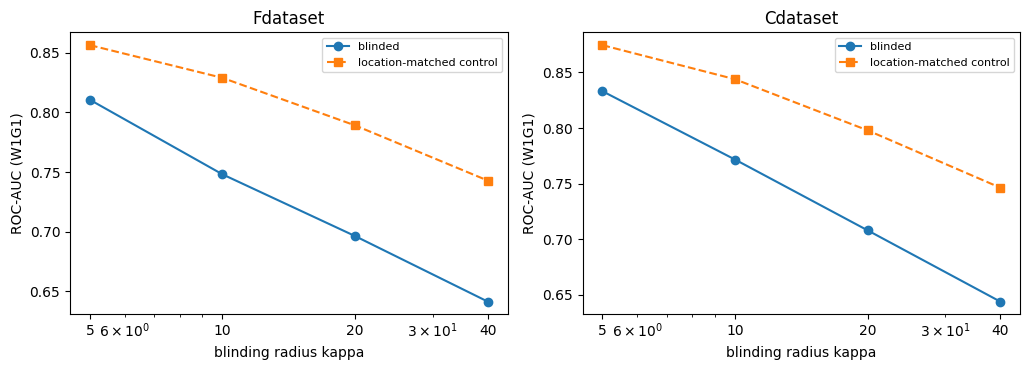

P4 (blinded AUC non-increasing in kappa and gap <= -0.03 at every radius): {'Fdataset': True, 'Cdataset': True}


In [11]:
def run_dose():
    global RES
    for t, D in DATA.items():
        seed = SEEDS[0]; folds = make_folds(D["Y"], seed)
        for f in DOSE_FOLDS:
            if done("dose", D["name"], seed, f): continue
            T = folds[f]; rows = []; t0 = time.time()
            for kap in DOSE_KAPPAS:
                reg, cnt = build_regimes(D, T, kap, seed, f)
                for regime in ("near", "loc"):
                    auc, aupr, it, cv, el = run_condition(reg[regime], T, D, "W1G1", seed, f)
                    rows.append(dict(dataset=D["name"], block="dose", seed=seed, fold=f, regime=regime, kappa=kap, cond="W1G1",
                                     auc=auc, aupr=aupr, iters=it, converged=cv, removed=cnt[regime], time_s=el))
            RES = pd.concat([RES, pd.DataFrame(rows)], ignore_index=True); save()
            print(f"[{D['name']}] dose-response fold {f} done in {time.time() - t0:.0f}s", flush=True)
run_dose()

DOSE_OK, dose_rows = {}, []
fig, axs = plt.subplots(1, len(DATA), figsize=(5.2 * len(DATA), 3.8), squeeze=False)
for ax, (t, D) in zip(axs[0], DATA.items()):
    d = RES[(RES.dataset == D["name"]) & (RES.block == "dose")]
    pv = d.pivot_table(index=["seed", "fold", "kappa"], columns="regime", values="auc").reset_index()
    pv["gap"] = pv["near"] - pv["loc"]
    g = pv.groupby("kappa").agg(blinded=("near", "mean"), control=("loc", "mean"), gap=("gap", "mean"), gap_sd=("gap", "std"), splits=("gap", "count"))
    removed = d[d.regime == "near"].groupby("kappa").removed.mean(); g["labels_removed"] = removed
    display(g.round(4).assign(dataset=D["name"]))
    mono = bool(np.all(np.diff(g["blinded"].values) <= 1e-3))
    DOSE_OK[D["name"]] = bool(mono and (g["gap"] <= THR["P4_gap"]).all())
    ax.plot(g.index, g["blinded"], "o-", label="blinded"); ax.plot(g.index, g["control"], "s--", label="location-matched control")
    ax.set_xscale("log"); ax.set_xticks(list(g.index)); ax.set_xticklabels([str(k) for k in g.index]); ax.set_xlabel("blinding radius kappa"); ax.set_ylabel("ROC-AUC (W1G1)")
    ax.set_title(D["name"]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("P4 (blinded AUC non-increasing in kappa and gap <= %.2f at every radius):" % THR["P4_gap"], DOSE_OK)

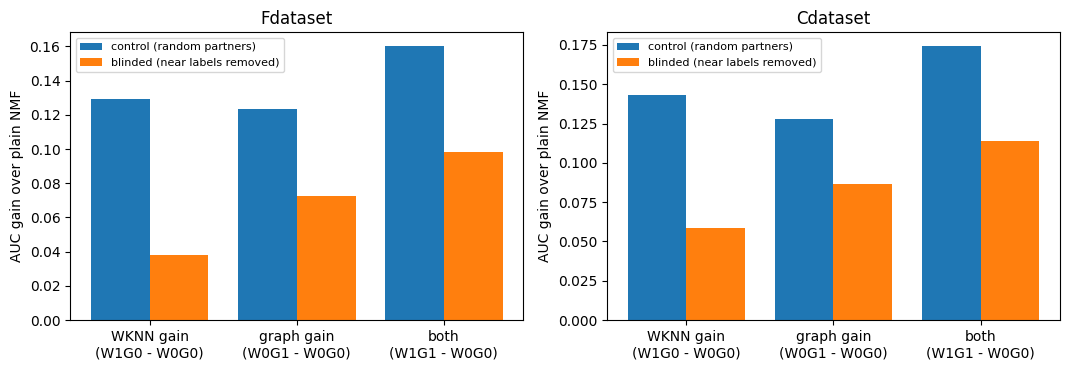

In [12]:
# ---- figure: component gains, blinded vs location-matched control
fig, axs = plt.subplots(1, len(DATA), figsize=(5.4 * len(DATA), 3.8), squeeze=False)
for ax, (t, D) in zip(axs[0], DATA.items()):
    W = wide(D["name"]); labels, ctrl, blind = ["WKNN gain\n(W1G0 - W0G0)", "graph gain\n(W0G1 - W0G0)", "both\n(W1G1 - W0G0)"], [], []
    for c in ("W1G0", "W0G1", "W1G1"):
        ctrl.append((W[("loc", c)] - W[("loc", "W0G0")]).mean()); blind.append((W[("near", c)] - W[("near", "W0G0")]).mean())
    x = np.arange(3); ax.bar(x - 0.2, ctrl, 0.4, label="control (random partners)"); ax.bar(x + 0.2, blind, 0.4, label="blinded (near labels removed)")
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("AUC gain over plain NMF"); ax.set_title(D["name"]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
## Verdict

In [13]:
conv_rate = float(RES[RES.iters > 0].converged.astype(bool).mean())
verd = []
for ds in CRIT:
    c = CRIT[ds]
    verd.append(dict(dataset=ds, P1=c["P1"], P2=c["P2"], P3=c["P3"], P4=DOSE_OK.get(ds)))
V = pd.DataFrame(verd).set_index("dataset"); display(V)

allP = lambda k: bool(V[k].all())
if allP("P1") and allP("P2") and allP("P3") and allP("P4"):  VERDICT = "SUPPORTED (strong): all of P1-P4 hold on every dataset"
elif allP("P1") and allP("P2") and allP("P3"):               VERDICT = "SUPPORTED: P1-P3 hold on every dataset (dose-response P4 did not fully hold)"
elif allP("P1"):                                             VERDICT = "PARTIAL: the full model relies on near labels (P1), but not every mechanistic criterion holds: " + ", ".join(k for k in ("P2", "P3") if not allP(k))
elif all(CRIT[d]["P1_weak"] for d in CRIT):                  VERDICT = "WEAKENED: the proximity penalty is negligible on every dataset"
else:                                                        VERDICT = "INCONCLUSIVE"
print("RH11 verdict:", VERDICT)
print(f"Proposition 1 exact check: {'PASS' if P1_EXACT else 'FAIL'} | Proposition 2 exact check: {'PASS' if P2_EXACT else 'FAIL'} | convergence rate of all fits: {conv_rate:.1%}")
if conv_rate < 0.95:
    print("WARNING: fewer than 95% of fits converged; raise MAXIT before interpreting the verdict.")
display(SUMMARY.round(4))
SUMMARY.to_csv(os.path.join(OUT_DIR, f"rh11_summary_{PROFILE}.csv"), index=False)

,P1,P2,P3,P4
dataset,,,,
Fdataset,True,True,False,True
Cdataset,True,False,True,True


RH11 verdict: PARTIAL: the full model relies on near labels (P1), but not every mechanistic criterion holds: P2, P3
Proposition 1 exact check: PASS | Proposition 2 exact check: PASS | convergence rate of all fits: 100.0%


,dataset,pen_W1G1,pen_W1G1_hi,pen_W0G0,did,did_hi,wknn_gain_blind,wknn_gain_ctrl,wknn_ratio,wknn_ratio_hi,graph_gain_blind,graph_gain_ctrl
0,Fdataset,-0.0809,-0.0493,-0.0192,-0.0617,-0.0093,0.0380,0.1291,0.2941,0.4733,0.0723,0.1233
1,Cdataset,-0.0723,-0.0328,-0.0119,-0.0604,-0.0222,0.0587,0.1429,0.4107,0.4772,0.0866,0.1279


## Reading the result and its limits

* **What a SUPPORTED verdict means.** The reported performance of WNMFDDA contains a component that exists only where labelled near neighbours exist, and the WKNN module is, to the precision of Proposition 1, a pure proximity channel. It does **not** mean the model is useless: the boundary report shows how much signal the factorised model keeps under blinding.
* **What it does not show.** (a) The blinding uses the model's *own* similarity matrices, so it removes exactly the evidence the model propagates through; that makes it a clean test of the mechanism but also a stress test chosen against the model. (b) The paper's parameters ($\lambda=1$, $\beta=0.02$, $K=p=5$) were selected under random-pair CV and are **not** re-tuned for the blinded regime; a model re-tuned under blinding could lose less. (c) Plain NMF also loses some AUC under blinding, which is why the claim rests on the difference-in-differences and not on the raw drop. (d) Two benchmark datasets, one split design, negatives are all unobserved pairs (some are undiscovered positives), so absolute AUCs are lower-bound style.
* **Natural follow-up.** Re-tune $(\lambda,\beta,K,p)$ on blinded development folds and repeat; if the penalty shrinks below the P1 threshold, the weakness is one of *tuning protocol*, otherwise it is intrinsic to the architecture.